# **Import libreries and set default values**

In [1]:
import math
import torch
import random
import numpy as np
from torch import nn, optim
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
from torchvision import datasets, transforms

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# **Load MNIST, create DataLoaders and Functaions**

In [2]:
batch_size = 128

transform = transforms.Compose([
    transforms.ToTensor(),  # [0, 1]
])

train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_data  = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_data,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print("Train samples:", len(train_data))
print("Test samples:", len(test_data))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.18MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.3MB/s]

Train samples: 60000
Test samples: 10000


**Show a sample**

Batch x: torch.Size([128, 1, 28, 28]) 0.0 1.0
Batch y: torch.Size([128])


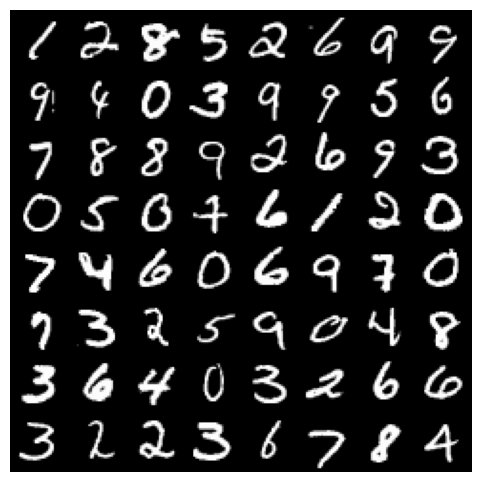

In [3]:
x, y = next(iter(train_loader))

print("Batch x:", x.shape, x.min().item(), x.max().item())
print("Batch y:", y.shape)

plt.figure(figsize=(6, 6))
plt.axis("off")
plt.imshow(make_grid(x[:64], nrow=8).permute(1, 2, 0), cmap="gray")
plt.show()

**Define visulization functaions**

In [4]:
def show_samples(img_batch, nrow=8, title=None):
    img_batch = img_batch.detach().cpu()
    grid = make_grid(img_batch, nrow=nrow, padding=2)
    plt.figure(figsize=(6, 6))
    if title:
        plt.title(title)
    plt.axis("off")
    plt.imshow(grid.permute(1, 2, 0), cmap="gray")
    plt.show()


def sample_grid_from_model(sample_fn, n_samples=64, nrow=8, title=None):
    imgs = sample_fn(n_samples)
    show_samples(imgs, nrow=nrow, title=title)

def _grid_img(img_batch, nrow=10):
    img_batch = img_batch.detach().cpu()
    grid = make_grid(img_batch, nrow=nrow, padding=2)   # (C,H,W)
    grid = grid.permute(1, 2, 0).numpy()                # (H,W,C)
    if grid.shape[2] == 1:
        grid = grid[:, :, 0]                            # (H,W) for grayscale
    return grid

# **VAE model**

In [5]:
z_dim = 32
enc_feat_dim = 128

class VAE(nn.Module):
    def __init__(self, z_dim=32, enc_feat_dim=128):
        super().__init__()
        self.z_dim = z_dim

        # Encoder: 28x28 -> 14x14 -> 7x7
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),   # 28 -> 14
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 14 -> 7
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, enc_feat_dim),
            nn.ReLU(),
        )

        self.mu = nn.Linear(enc_feat_dim, z_dim)
        self.logvar = nn.Linear(enc_feat_dim, z_dim)

        # Decoder: z -> 32x7x7 -> 14x14 -> 28x28
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 32 * 7 * 7),
            nn.ReLU(),
            nn.Unflatten(1, (32, 7, 7)),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),  # 7 -> 14
            nn.ReLU(),
            nn.ConvTranspose2d(16, 8, kernel_size=4, stride=2, padding=1),   # 14 -> 28
            nn.ReLU(),
            nn.ConvTranspose2d(8, 1, kernel_size=3, stride=1, padding=1),    # 28 -> 28
            nn.Sigmoid(),
            nn.Flatten()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu = self.mu(h)
        logvar = self.logvar(h)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decoder(z).view(-1, 1, 28, 28)
        return x_hat, mu, logvar

    @torch.no_grad()
    def sample(self, n, device):
        z = torch.randn(n, self.z_dim, device=device)
        x = self.decoder(z).view(-1, 1, 28, 28)
        return x

vae = VAE(z_dim=z_dim, enc_feat_dim=enc_feat_dim).to(device)
print(vae)

VAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=3136, out_features=128, bias=True)
    (6): ReLU()
  )
  (mu): Linear(in_features=128, out_features=32, bias=True)
  (logvar): Linear(in_features=128, out_features=32, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=1568, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(32, 7, 7))
    (3): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(16, 8, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): ReLU()
    (7): ConvTranspose2d(8, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): Sigmoid()
    (9): Flatten(start_dim=1, end_dim=-1)
  )
)


**VAE loss + optimizer**

In [6]:
lr_vae = 1e-3
vae_opt = optim.Adam(vae.parameters(), lr=lr_vae)

def vae_loss(x_hat, x, mu, logvar):
    bce = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (bce + kl) / x.size(0)

fixed_z_vae = torch.randn(64, z_dim, device=device)

@torch.no_grad()
def vae_sample_fn(n_samples):
    return vae.sample(n_samples, device)

**Train the VAE**

VAE | epoch 01/50 | loss: 203.6181


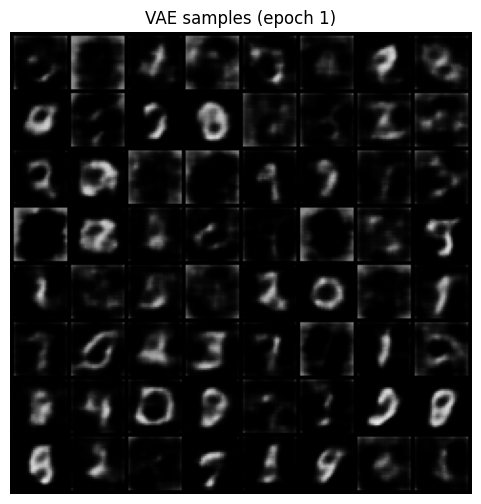

VAE | epoch 02/50 | loss: 132.3405


VAE | epoch 03/50 | loss: 117.7340


VAE | epoch 04/50 | loss: 111.4402


VAE | epoch 05/50 | loss: 108.2078


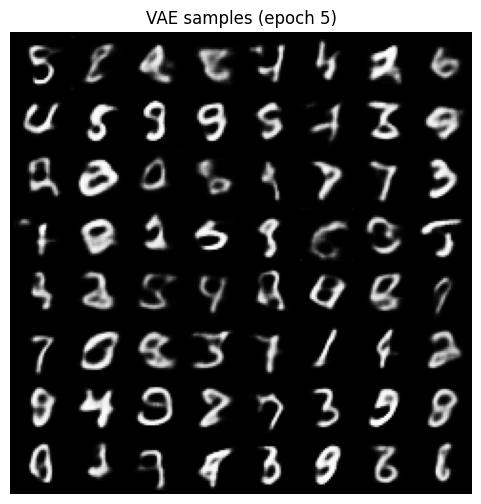

VAE | epoch 06/50 | loss: 106.2314


VAE | epoch 07/50 | loss: 104.8810


VAE | epoch 08/50 | loss: 103.9156


VAE | epoch 09/50 | loss: 103.1620


VAE | epoch 10/50 | loss: 102.6480


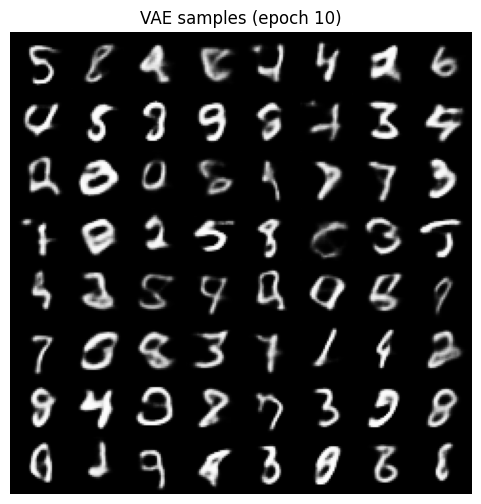

VAE | epoch 11/50 | loss: 102.1844


VAE | epoch 12/50 | loss: 101.7402


VAE | epoch 13/50 | loss: 101.3778


VAE | epoch 14/50 | loss: 101.0373


VAE | epoch 15/50 | loss: 100.7549


...

VAE | epoch 21/50 | loss: 99.6549


VAE | epoch 22/50 | loss: 99.5811


VAE | epoch 23/50 | loss: 99.3475


VAE | epoch 24/50 | loss: 99.2168


VAE | epoch 25/50 | loss: 99.1991


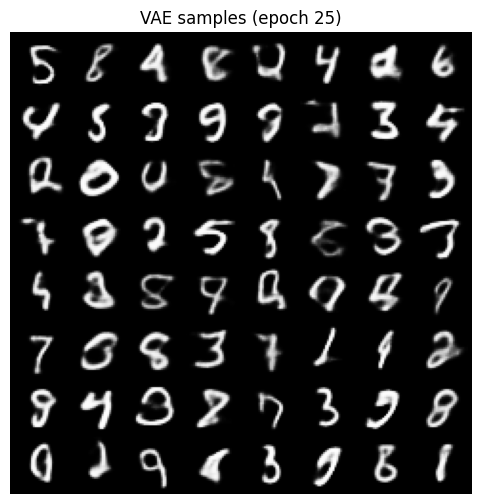

VAE | epoch 26/50 | loss: 99.0345


VAE | epoch 27/50 | loss: 98.9748


VAE | epoch 28/50 | loss: 98.8367


VAE | epoch 29/50 | loss: 98.7753


VAE | epoch 30/50 | loss: 98.7032


...

VAE | epoch 46/50 | loss: 97.7322


VAE | epoch 47/50 | loss: 97.7033


VAE | epoch 48/50 | loss: 97.6652


VAE | epoch 49/50 | loss: 97.6815


VAE | epoch 50/50 | loss: 97.5914


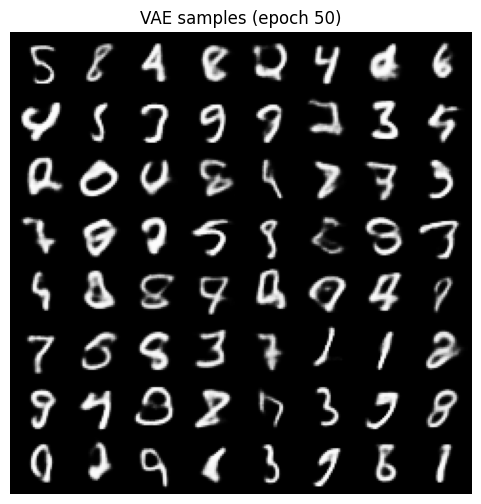

In [7]:
epochs_vae = 50
vae_train_losses = []

for epoch in range(1, epochs_vae + 1):
    vae.train()
    running = 0.0

    for x, _ in train_loader:
        x = x.to(device)

        x_hat, mu, logvar = vae(x)
        loss = vae_loss(x_hat, x, mu, logvar)

        vae_opt.zero_grad()
        loss.backward()
        vae_opt.step()

        running += loss.item()

    avg_loss = running / len(train_loader)
    vae_train_losses.append(avg_loss)

    vae.eval()
    with torch.no_grad():
        samples = vae.decoder(fixed_z_vae).view(-1, 1, 28, 28)

    print(f"VAE | epoch {epoch:02d}/{epochs_vae} | loss: {avg_loss:.4f}")
    show_samples(samples, nrow=8, title=f"VAE samples (epoch {epoch})")

**VAE loss curve**

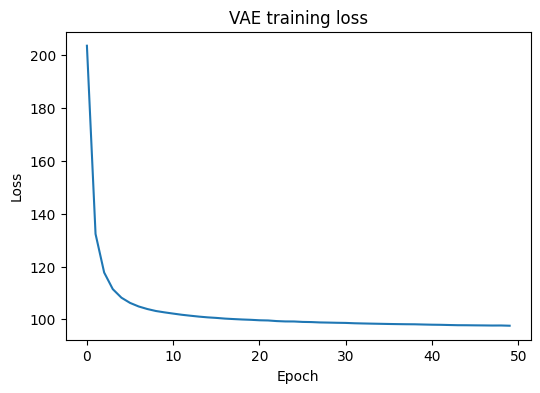

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(vae_train_losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE training loss")
plt.show()

**VAE reconstructions (real vs reconstructed)**

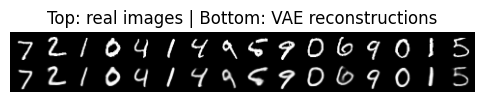

In [9]:
vae.eval()

x, _ = next(iter(test_loader))
x = x.to(device)[:16]

with torch.no_grad():
    x_hat, _, _ = vae(x)

pairs = torch.cat([x, x_hat], dim=0)
show_samples(pairs, nrow=16, title="Top: real images | Bottom: VAE reconstructions")

# **GAN model**

In [10]:
class Generator(nn.Module):
    def __init__(self, z_dim=32):
        super().__init__()
        self.z_dim = z_dim

        self.fc = nn.Sequential(
            nn.Linear(z_dim, 128 * 7 * 7),
            nn.ReLU()
        )

        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # 7 -> 14
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),    # 14 -> 28
            nn.Sigmoid()
        )

    def forward(self, z):
        x = self.fc(z).view(-1, 128, 7, 7)
        x = self.deconv(x)
        return x


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),  # 28 -> 14
            nn.LeakyReLU(0.2),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 14 -> 7
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
        )

        self.fc = nn.Linear(128 * 7 * 7, 1)

    def forward(self, x):
        h = self.conv(x).view(x.size(0), -1)
        logits = self.fc(h)
        return logits


G = Generator(z_dim=z_dim).to(device)
D = Discriminator().to(device)

print(G)
print(D)

Generator(
  (fc): Sequential(
    (0): Linear(in_features=32, out_features=6272, bias=True)
    (1): ReLU()
  )
  (deconv): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): Sigmoid()
  )
)
Discriminator(
  (conv): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2)
  )
  (fc): Linear(in_features=6272, out_features=1, bias=True)
)


**GAN loss + optimizers + sampling function**

In [11]:

lr_gan = 2e-4
betas = (0.5, 0.999)

g_opt = optim.Adam(G.parameters(), lr=lr_gan, betas=betas)
d_opt = optim.Adam(D.parameters(), lr=lr_gan, betas=betas)

fixed_z_gan = torch.randn(64, z_dim, device=device)

def d_loss_fn(real_logits, fake_logits):
    real_loss = F.binary_cross_entropy_with_logits(real_logits, torch.ones_like(real_logits))
    fake_loss = F.binary_cross_entropy_with_logits(fake_logits, torch.zeros_like(fake_logits))
    return real_loss + fake_loss

def g_loss_fn(fake_logits):
    return F.binary_cross_entropy_with_logits(fake_logits, torch.ones_like(fake_logits))

@torch.no_grad()
def gan_sample_fn(n_samples):
    G.eval()
    z = torch.randn(n_samples, z_dim, device=device)
    return G(z)

**Train the GAN**

GAN | epoch 01/50 | D: 0.2587 | G: 3.1822


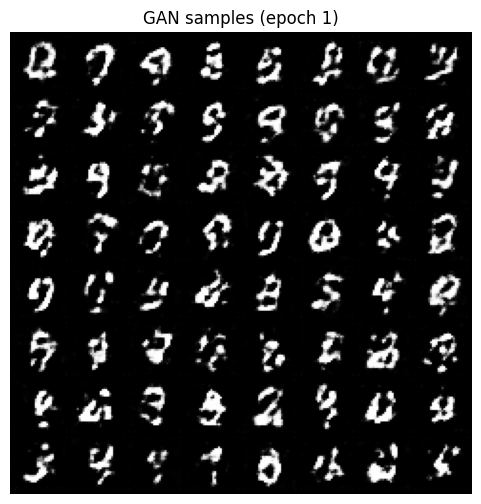

GAN | epoch 02/50 | D: 0.3094 | G: 2.4757


GAN | epoch 03/50 | D: 0.2461 | G: 2.7795


GAN | epoch 04/50 | D: 0.3390 | G: 2.5654


GAN | epoch 05/50 | D: 0.3609 | G: 2.4696


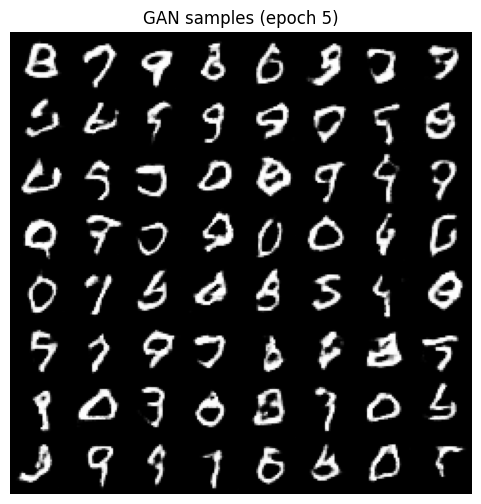

GAN | epoch 06/50 | D: 0.3806 | G: 2.4112


GAN | epoch 07/50 | D: 0.4048 | G: 2.3745


GAN | epoch 08/50 | D: 0.4107 | G: 2.3686


GAN | epoch 09/50 | D: 0.4218 | G: 2.3671


GAN | epoch 10/50 | D: 0.4255 | G: 2.3841


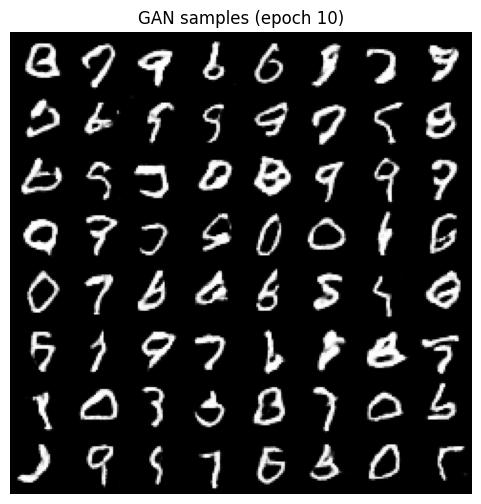

GAN | epoch 11/50 | D: 0.4174 | G: 2.4107


GAN | epoch 12/50 | D: 0.4317 | G: 2.4278


GAN | epoch 13/50 | D: 0.4282 | G: 2.4414


GAN | epoch 14/50 | D: 0.4228 | G: 2.4737


GAN | epoch 15/50 | D: 0.4164 | G: 2.4925


...

GAN | epoch 21/50 | D: 0.4037 | G: 2.6197


GAN | epoch 22/50 | D: 0.4120 | G: 2.6419


GAN | epoch 23/50 | D: 0.3884 | G: 2.6434


GAN | epoch 24/50 | D: 0.3941 | G: 2.6632


GAN | epoch 25/50 | D: 0.4021 | G: 2.6904


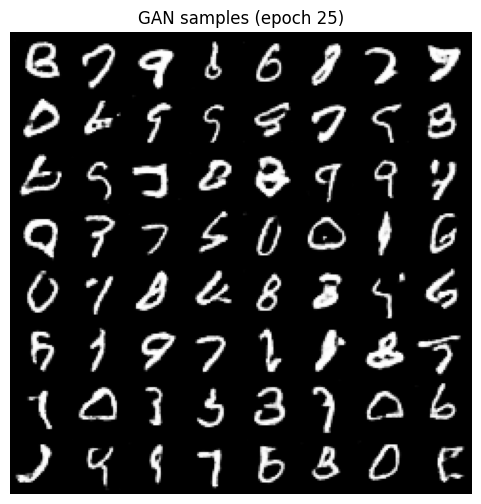

GAN | epoch 26/50 | D: 0.3976 | G: 2.6957


GAN | epoch 27/50 | D: 0.3962 | G: 2.7052


GAN | epoch 28/50 | D: 0.3876 | G: 2.7593


GAN | epoch 29/50 | D: 0.3881 | G: 2.7414


GAN | epoch 30/50 | D: 0.3956 | G: 2.7488


...

GAN | epoch 46/50 | D: 0.3905 | G: 2.8769


GAN | epoch 47/50 | D: 0.4045 | G: 2.8526


GAN | epoch 48/50 | D: 0.3915 | G: 2.8413


GAN | epoch 49/50 | D: 0.3839 | G: 2.8871


GAN | epoch 50/50 | D: 0.3854 | G: 2.8872


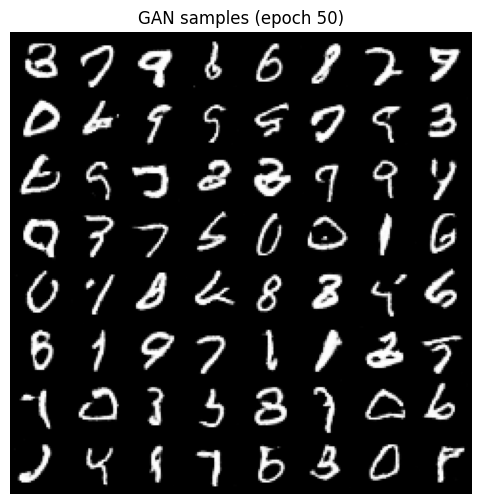

In [12]:
def set_requires_grad(model, flag):
    for p in model.parameters():
        p.requires_grad_(flag)

epochs_gan = 50
d_losses, g_losses = [], []

for epoch in range(1, epochs_gan + 1):
    G.train()
    D.train()
    d_run, g_run = 0.0, 0.0

    for real, _ in train_loader:
        real = real.to(device)
        b = real.size(0)

        # Discriminator step
        set_requires_grad(D, True)

        z = torch.randn(b, z_dim, device=device)
        fake = G(z).detach()

        real_logits = D(real)
        fake_logits = D(fake)
        d_loss = d_loss_fn(real_logits, fake_logits)

        d_opt.zero_grad()
        d_loss.backward()
        d_opt.step()

        # Generator step (freeze D)
        set_requires_grad(D, False)

        z = torch.randn(b, z_dim, device=device)
        fake = G(z)
        fake_logits = D(fake)
        g_loss = g_loss_fn(fake_logits)

        g_opt.zero_grad()
        g_loss.backward()
        g_opt.step()

        d_run += d_loss.item()
        g_run += g_loss.item()

    d_avg = d_run / len(train_loader)
    g_avg = g_run / len(train_loader)
    d_losses.append(d_avg)
    g_losses.append(g_avg)

    G.eval()
    with torch.no_grad():
        samples = G(fixed_z_gan)

    print(f"GAN | epoch {epoch:02d}/{epochs_gan} | D: {d_avg:.4f} | G: {g_avg:.4f}")
    show_samples(samples, nrow=8, title=f"GAN samples (epoch {epoch})")

**GAN loss curves**

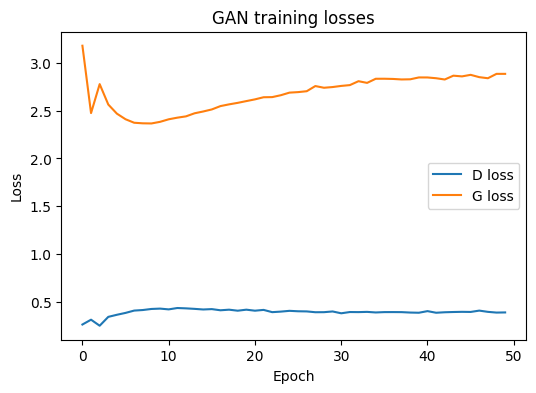

In [13]:
plt.figure(figsize=(6, 4))
plt.plot(d_losses, label="D loss")
plt.plot(g_losses, label="G loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN training losses")
plt.legend()
plt.show()

# **MNIST classifier (for feature extraction + label stats)**

In [14]:
class MNIST_CNN(nn.Module):
    def __init__(self, feat_dim=128):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 28 -> 14

            nn.Conv2d(32, 64, 3, 1, 1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 14 -> 7
        )
        self.fc1 = nn.Linear(64 * 7 * 7, feat_dim)
        self.fc2 = nn.Linear(feat_dim, 10)

    def forward(self, x, return_features=False):
        h = self.conv(x).view(x.size(0), -1)
        feat = torch.relu(self.fc1(h))
        logits = self.fc2(feat)
        if return_features:
            return logits, feat
        return logits


clf = MNIST_CNN(feat_dim=128).to(device)
clf_opt = optim.Adam(clf.parameters(), lr=1e-3)
clf_epochs = 5

for epoch in range(1, clf_epochs + 1):
    clf.train()
    total_loss = 0.0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = clf(x)
        loss = F.cross_entropy(logits, y)

        clf_opt.zero_grad()
        loss.backward()
        clf_opt.step()

        total_loss += loss.item()

    clf.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            pred = clf(x).argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    acc = correct / total
    print(f"Classifier | epoch {epoch}/{clf_epochs} | loss: {total_loss/len(train_loader):.4f} | acc: {acc:.4f}")

Classifier | epoch 1/5 | loss: 0.2301 | acc: 0.9819
Classifier | epoch 2/5 | loss: 0.0601 | acc: 0.9860
Classifier | epoch 3/5 | loss: 0.0408 | acc: 0.9872
Classifier | epoch 4/5 | loss: 0.0311 | acc: 0.9914
Classifier | epoch 5/5 | loss: 0.0240 | acc: 0.9899


# **Comparison and conclusion**

**Parameter counts (fairness check)**

In [15]:
def set_requires_grad(model, flag):
    for p in model.parameters():
        p.requires_grad_(flag)

set_requires_grad(D, True)  # make sure D is unfrozen when counting
def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

vae_p = count_params(vae)
g_p   = count_params(G)
d_p   = count_params(D)

print("VAE params:", vae_p)
print("G params  :", g_p)
print("D params  :", d_p)
print("GAN total :", g_p + d_p)
print("VAE / GAN total ratio:", vae_p / (g_p + d_p))

VAE params: 505249
G params  : 339265
D params  : 138817
GAN total : 478082
VAE / GAN total ratio: 1.056824979815178


FID-like (Frechet) + label diversity on generated samples

In [16]:
from scipy.linalg import sqrtm

@torch.no_grad()
def get_real_features(loader):
    feats = []
    for x, _ in loader:
        x = x.to(device)
        _, f = clf(x, return_features=True)
        feats.append(f.cpu())
    return torch.cat(feats, dim=0).numpy()

@torch.no_grad()
def get_gen_features_labels_images(sample_fn, n_samples, batch=256):
    feats, labels, imgs = [], [], []
    left = n_samples

    while left > 0:
        b = min(batch, left)
        x = sample_fn(b).to(device)
        logits, f = clf(x, return_features=True)

        imgs.append(x.detach().cpu())
        feats.append(f.cpu())
        labels.append(logits.argmax(dim=1).cpu())
        left -= b

    imgs = torch.cat(imgs, dim=0)
    feats = torch.cat(feats, dim=0).numpy()
    labels = torch.cat(labels, dim=0).numpy()
    return feats, labels, imgs

def frechet_distance(feats_real, feats_fake, eps=1e-6):
    mu1, mu2 = feats_real.mean(axis=0), feats_fake.mean(axis=0)
    c1 = np.cov(feats_real, rowvar=False)
    c2 = np.cov(feats_fake, rowvar=False)

    c1 = c1 + np.eye(c1.shape[0]) * eps
    c2 = c2 + np.eye(c2.shape[0]) * eps

    covmean = sqrtm(c1 @ c2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    diff = mu1 - mu2
    return float(diff @ diff + np.trace(c1 + c2 - 2.0 * covmean))

def label_entropy(labels, n_classes=10):
    counts = np.bincount(labels, minlength=n_classes).astype(np.float64)
    p = counts / counts.sum()
    p = np.clip(p, 1e-12, 1.0)
    return float(-(p * np.log(p)).sum()), counts

real_feats = get_real_features(test_loader)

n_eval = 10000
vae_feats, vae_lbls, vae_imgs = get_gen_features_labels_images(vae_sample_fn, n_eval)
gan_feats, gan_lbls, gan_imgs = get_gen_features_labels_images(gan_sample_fn, n_eval)

vae_fd = frechet_distance(real_feats, vae_feats)
gan_fd = frechet_distance(real_feats, gan_feats)

vae_ent, vae_counts = label_entropy(vae_lbls)
gan_ent, gan_counts = label_entropy(gan_lbls)

print("\nResults (lower Frechet is better, higher entropy is better)")
print(f"VAE | Frechet: {vae_fd:.2f} | entropy: {vae_ent:.3f} | counts: {vae_counts}")
print(f"GAN | Frechet: {gan_fd:.2f} | entropy: {gan_ent:.3f} | counts: {gan_counts}")


Results (lower Frechet is better, higher entropy is better)
VAE | Frechet: 138.61 | entropy: 2.258 | counts: [ 610.  660. 1281. 1535.  999.  858.  637. 1024. 1108. 1288.]
GAN | Frechet: 50.38 | entropy: 2.290 | counts: [1084.  882.  756. 1142. 1002.  898.  770. 1219. 1208. 1039.]


**matrices side-by-side: 10 real test images per digit + 10 VAE per digit + 10 GAN per digit**

Saved: digit_matrices.png


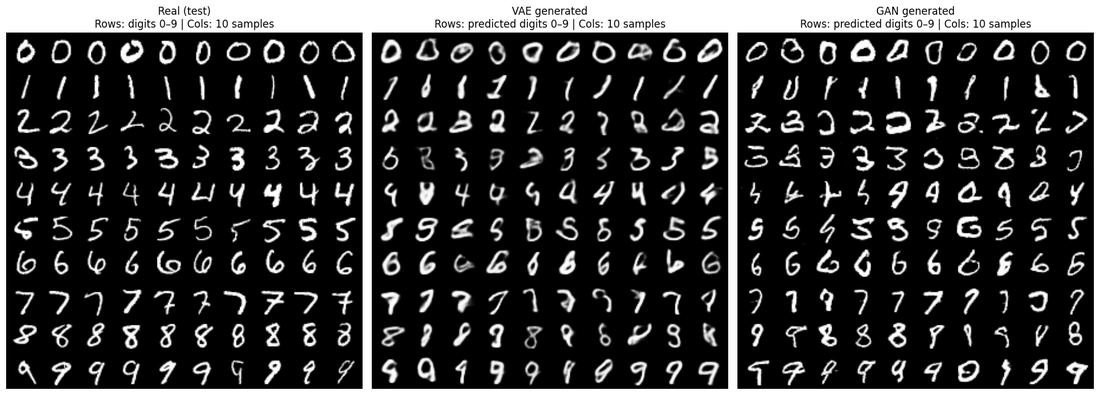

In [17]:
@torch.no_grad()
def collect_real_by_digit(loader, n_per_digit=10, n_classes=10):
    buckets = {d: [] for d in range(n_classes)}
    for x, y in loader:
        for d in range(n_classes):
            if len(buckets[d]) >= n_per_digit:
                continue
            mask = (y == d)
            if mask.any():
                buckets[d].append(x[mask].cpu())
        if all(sum(t.size(0) for t in buckets[d]) >= n_per_digit for d in range(n_classes)):
            break

    out = []
    for d in range(n_classes):
        imgs = torch.cat(buckets[d], dim=0)[:n_per_digit]
        out.append(imgs)
    return torch.stack(out, dim=0)  # (10, n_per_digit, 1, 28, 28)

@torch.no_grad()
def collect_gen_by_digit(sample_fn, n_per_digit=10, n_classes=10, batch=256, max_tries=500):
    clf.eval()
    buckets = {d: [] for d in range(n_classes)}
    tries = 0

    while tries < max_tries and not all(sum(t.size(0) for t in buckets[d]) >= n_per_digit for d in range(n_classes)):
        x = sample_fn(batch).to(device)
        logits = clf(x)
        preds = logits.argmax(dim=1)

        for d in range(n_classes):
            if sum(t.size(0) for t in buckets[d]) >= n_per_digit:
                continue
            mask = (preds == d)
            if mask.any():
                buckets[d].append(x[mask].detach().cpu())
        tries += 1

    out = []
    for d in range(n_classes):
        if len(buckets[d]) == 0:
            imgs = torch.zeros(n_per_digit, 1, 28, 28)
        else:
            imgs = torch.cat(buckets[d], dim=0)[:n_per_digit]
            if imgs.size(0) < n_per_digit:
                pad = torch.zeros(n_per_digit - imgs.size(0), 1, 28, 28)
                imgs = torch.cat([imgs, pad], dim=0)
        out.append(imgs)

    return torch.stack(out, dim=0)  # (10, n_per_digit, 1, 28, 28)

@torch.no_grad()
def make_digit_matrix_figure(n_per_digit=10, save_path="digit_matrices.png"):
    vae.eval()
    G.eval()
    clf.eval()

    real_mat = collect_real_by_digit(test_loader, n_per_digit=n_per_digit)
    vae_mat  = collect_gen_by_digit(vae_sample_fn, n_per_digit=n_per_digit)
    gan_mat  = collect_gen_by_digit(gan_sample_fn, n_per_digit=n_per_digit)

    def flatten_matrix(mat):
        # mat: (10, n, 1, 28, 28) -> (10*n, 1, 28, 28), row-major (digit 0 row first)
        return mat.reshape(-1, 1, 28, 28)

    real_grid = _grid_img(flatten_matrix(real_mat), nrow=n_per_digit)
    vae_grid  = _grid_img(flatten_matrix(vae_mat),  nrow=n_per_digit)
    gan_grid  = _grid_img(flatten_matrix(gan_mat),  nrow=n_per_digit)

    fig, axes = plt.subplots(1, 3, figsize=(18, 8))

    axes[0].imshow(real_grid, cmap="gray")
    axes[0].set_title("Real (test)\nRows: digits 0–9 | Cols: 10 samples")
    axes[0].axis("off")

    axes[1].imshow(vae_grid, cmap="gray")
    axes[1].set_title("VAE generated\nRows: predicted digits 0–9 | Cols: 10 samples")
    axes[1].axis("off")

    axes[2].imshow(gan_grid, cmap="gray")
    axes[2].set_title("GAN generated\nRows: predicted digits 0–9 | Cols: 10 samples")
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    print("Saved:", save_path)
    plt.show()

make_digit_matrix_figure(n_per_digit=10, save_path="digit_matrices.png")

**Precision & Recall in feature space (k-NN radius method)**

In [18]:
from sklearn.neighbors import NearestNeighbors

def precision_recall_knn(real_feats, fake_feats, k=3, n_sub=5000, seed=0):
    rng = np.random.default_rng(seed)
    m = min(n_sub, real_feats.shape[0], fake_feats.shape[0])

    ridx = rng.choice(real_feats.shape[0], size=m, replace=False)
    fidx = rng.choice(fake_feats.shape[0], size=m, replace=False)

    real = real_feats[ridx]
    fake = fake_feats[fidx]

    nn_real_k = NearestNeighbors(n_neighbors=k+1).fit(real)
    d_real, _ = nn_real_k.kneighbors(real)
    r_real = d_real[:, -1]

    nn_fake_k = NearestNeighbors(n_neighbors=k+1).fit(fake)
    d_fake, _ = nn_fake_k.kneighbors(fake)
    r_fake = d_fake[:, -1]

    nn_real_1 = NearestNeighbors(n_neighbors=1).fit(real)
    d_fr, idx_fr = nn_real_1.kneighbors(fake)
    precision = float(np.mean(d_fr[:, 0] <= r_real[idx_fr[:, 0]]))

    nn_fake_1 = NearestNeighbors(n_neighbors=1).fit(fake)
    d_rf, idx_rf = nn_fake_1.kneighbors(real)
    recall = float(np.mean(d_rf[:, 0] <= r_fake[idx_rf[:, 0]]))

    return precision, recall

vae_prec, vae_rec = precision_recall_knn(real_feats, vae_feats, k=3, n_sub=5000, seed=2)
gan_prec, gan_rec = precision_recall_knn(real_feats, gan_feats, k=3, n_sub=5000, seed=2)

print(f"Precision/Recall (higher is better)")
print(f"VAE | precision: {vae_prec:.3f} | recall: {vae_rec:.3f}")
print(f"GAN | precision: {gan_prec:.3f} | recall: {gan_rec:.3f}")

Precision/Recall (higher is better)
VAE | precision: 0.435 | recall: 0.572
GAN | precision: 0.337 | recall: 0.594


**TSTR utility: train a fresh classifier on generated data and test on real MNIST**

In [19]:
from torch.utils.data import TensorDataset

@torch.no_grad()
def make_pseudolabeled_dataset(sample_fn, n_samples=10000, batch=256):
    xs, ys = [], []
    left = n_samples

    clf.eval()
    while left > 0:
        b = min(batch, left)
        x = sample_fn(b).to(device)
        logits = clf(x)
        y = logits.argmax(dim=1)

        xs.append(x.cpu())
        ys.append(y.cpu())
        left -= b

    x_all = torch.cat(xs, dim=0)
    y_all = torch.cat(ys, dim=0)
    return TensorDataset(x_all, y_all)

def train_eval_tstr(dataset, test_loader, epochs=3, lr=1e-3, batch_size=128):
    model = MNIST_CNN(feat_dim=128).to(device)
    opt = optim.Adam(model.parameters(), lr=lr)

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    for _ in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            pred = model(x).argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

vae_gen_ds = make_pseudolabeled_dataset(vae_sample_fn, n_samples=10000)
gan_gen_ds = make_pseudolabeled_dataset(gan_sample_fn, n_samples=10000)

vae_tstr_acc = train_eval_tstr(vae_gen_ds, test_loader, epochs=3)
gan_tstr_acc = train_eval_tstr(gan_gen_ds, test_loader, epochs=3)

print(f"TSTR accuracy (higher is better)")
print(f"VAE -> test acc: {vae_tstr_acc:.4f}")
print(f"GAN -> test acc: {gan_tstr_acc:.4f}")

TSTR accuracy (higher is better)
VAE -> test acc: 0.9537
GAN -> test acc: 0.9422


 **Distinguishability margin (top-1 minus top-2)**

In [20]:
@torch.no_grad()
def margin_stats(sample_fn, n_samples=10000, batch=256):
    clf.eval()
    margins = []
    left = n_samples

    while left > 0:
        b = min(batch, left)
        x = sample_fn(b).to(device)
        p = torch.softmax(clf(x), dim=1)                 # [b, 10]
        top2 = torch.topk(p, k=2, dim=1).values          # [b, 2]
        m = (top2[:, 0] - top2[:, 1]).cpu()              # [b]
        margins.append(m)
        left -= b

    margins = torch.cat(margins, dim=0).numpy()
    return {
        "mean": float(margins.mean()),
        "median": float(np.median(margins)),
        "p10": float(np.percentile(margins, 10)),
        "p90": float(np.percentile(margins, 90)),
    }

vae_margin = margin_stats(vae_sample_fn, n_samples=n_eval)
gan_margin = margin_stats(gan_sample_fn, n_samples=n_eval)

print("Distinguishability (top1 - top2 margin) | higher is better")
print(f"VAE | mean: {vae_margin['mean']:.3f} | med: {vae_margin['median']:.3f} | p10: {vae_margin['p10']:.3f} | p90: {vae_margin['p90']:.3f}")
print(f"GAN | mean: {gan_margin['mean']:.3f} | med: {gan_margin['median']:.3f} | p10: {gan_margin['p10']:.3f} | p90: {gan_margin['p90']:.3f}")

Distinguishability (top1 - top2 margin) | higher is better
VAE | mean: 0.780 | med: 0.941 | p10: 0.262 | p90: 1.000
GAN | mean: 0.834 | med: 0.986 | p10: 0.355 | p90: 1.000


**Simple comparison plots (label distribution)**

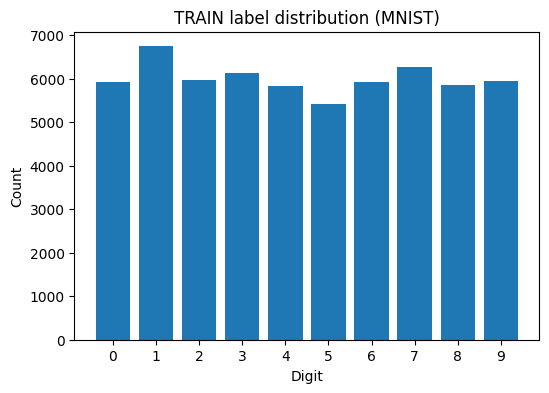

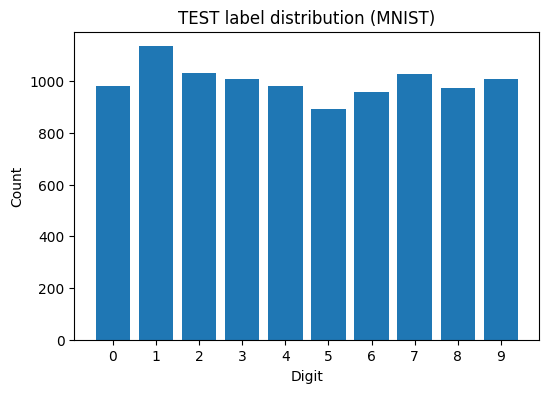

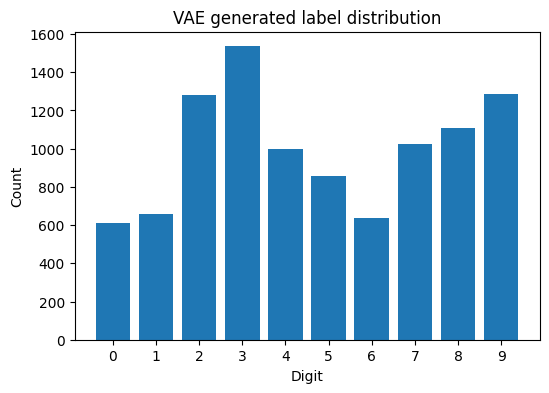

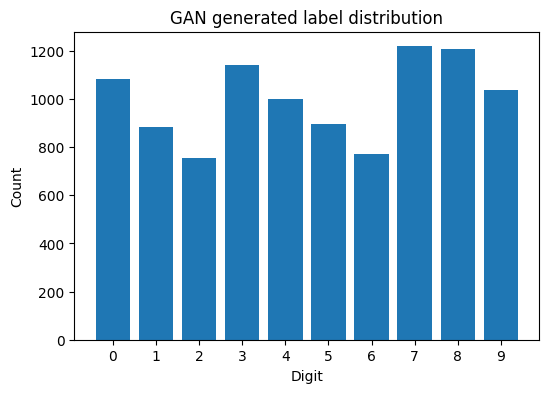

In [21]:
# Label distribution for TRAIN, TEST, VAE-generated, GAN-generated (same style)

def count_labels_from_loader(loader, n_classes=10):
    counts = np.zeros(n_classes, dtype=np.int64)
    for _, y in loader:
        y = y.numpy()
        counts += np.bincount(y, minlength=n_classes)
    return counts

train_counts = count_labels_from_loader(train_loader)
test_counts  = count_labels_from_loader(test_loader)

digits = np.arange(10)

plt.figure(figsize=(6, 4))
plt.bar(digits, train_counts)
plt.xticks(digits)
plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("TRAIN label distribution (MNIST)")
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(digits, test_counts)
plt.xticks(digits)
plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("TEST label distribution (MNIST)")
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(digits, vae_counts)
plt.xticks(digits)
plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("VAE generated label distribution")
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(digits, gan_counts)
plt.xticks(digits)
plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("GAN generated label distribution")
plt.show()

**Classifier confidence**

In [22]:
@torch.no_grad()
def classifier_confidence(sample_fn, n_samples=10000, batch=256, threshold=0.5):
    vals = []
    left = n_samples

    clf.eval()
    while left > 0:
        b = min(batch, left)
        x = sample_fn(b).to(device)
        p = torch.softmax(clf(x), dim=1)
        vals.append(p.max(dim=1).values.cpu())
        left -= b

    vals = torch.cat(vals, dim=0).numpy()
    mean_conf = float(vals.mean())
    frac_high = float((vals > threshold).mean())
    return mean_conf, frac_high

conf_th = 0.5

vae_conf_mean, vae_conf_frac = classifier_confidence(vae_sample_fn, n_samples=n_eval, threshold=conf_th)
gan_conf_mean, gan_conf_frac = classifier_confidence(gan_sample_fn, n_samples=n_eval, threshold=conf_th)

print("\nClassifier confidence (max softmax)")
print(f"VAE | mean: {vae_conf_mean:.3f} | fraction > {conf_th}: {vae_conf_frac:.3f}")
print(f"GAN | mean: {gan_conf_mean:.3f} | fraction > {conf_th}: {gan_conf_frac:.3f}")


Classifier confidence (max softmax)
VAE | mean: 0.872 | fraction > 0.5: 0.953
GAN | mean: 0.909 | fraction > 0.5: 0.975


**Conclusion**

In [23]:
def _has(name):
    return name in globals()

def _to_float(x):
    if x is None:
        return None
    try:
        x = float(x)
        if math.isnan(x) or math.isinf(x):
            return None
        return x
    except Exception:
        return None

def fmt(x, p=3, none="N/A"):
    x = _to_float(x)
    return none if x is None else f"{x:.{p}f}"

def better(vae, gan, higher_is_better=True, tol=1e-12):
    vae = _to_float(vae); gan = _to_float(gan)
    if vae is None or gan is None:
        return "N/A"
    if abs(vae - gan) <= tol:
        return "Tie"
    if higher_is_better:
        return "VAE" if vae > gan else "GAN"
    else:
        return "VAE" if vae < gan else "GAN"

def better_closer_to_real(vae, gan, real, tol=1e-12):
    vae = _to_float(vae); gan = _to_float(gan); real = _to_float(real)
    if vae is None or gan is None or real is None:
        return "N/A"
    d_vae = abs(vae - real)
    d_gan = abs(gan - real)
    if abs(d_vae - d_gan) <= tol:
        return "Tie"
    return "VAE" if d_vae < d_gan else "GAN"


better_fd   = better(globals().get("vae_fd"), globals().get("gan_fd"), higher_is_better=False)
better_ent  = better(globals().get("vae_ent"), globals().get("gan_ent"), higher_is_better=True)
better_is   = better(globals().get("vae_is_mean"), globals().get("gan_is_mean"), higher_is_better=True)
better_prec = better(globals().get("vae_prec"), globals().get("gan_prec"), higher_is_better=True)
better_rec  = better(globals().get("vae_rec"), globals().get("gan_rec"), higher_is_better=True)
better_tstr = better(globals().get("vae_tstr_acc"), globals().get("gan_tstr_acc"), higher_is_better=True)
better_conf = better(globals().get("vae_conf_mean"), globals().get("gan_conf_mean"), higher_is_better=True)

better_div  = better_closer_to_real(
    globals().get("vae_div"), globals().get("gan_div"), globals().get("real_div")
)



conclusion = f"""
## Results Summary (MNIST)

### Quantitative (distribution + diversity)
- VAE | Frechet: {fmt(globals().get("vae_fd"), 2)} (lower is better) | KID: {fmt(globals().get("vae_kid_mean"), 6)} ± {fmt(globals().get("vae_kid_std"), 6)} (lower is better)
- GAN | Frechet: {fmt(globals().get("gan_fd"), 2)} (lower is better) | KID: {fmt(globals().get("gan_kid_mean"), 6)} ± {fmt(globals().get("gan_kid_std"), 6)} (lower is better)

- VAE | Label entropy: {fmt(globals().get("vae_ent"), 3)} (higher is better) | Precision: {fmt(globals().get("vae_prec"), 3)} | Recall: {fmt(globals().get("vae_rec"), 3)}
- GAN | Label entropy: {fmt(globals().get("gan_ent"), 3)} (higher is better) | Precision: {fmt(globals().get("gan_prec"), 3)} | Recall: {fmt(globals().get("gan_rec"), 3)}

- VAE | Inception Score: {fmt(globals().get("vae_is_mean"), 3)} ± {fmt(globals().get("vae_is_std"), 3)} (higher is better)
- GAN | Inception Score: {fmt(globals().get("gan_is_mean"), 3)} ± {fmt(globals().get("gan_is_std"), 3)} (higher is better)

### Classifier confidence
- VAE | mean max-softmax: {fmt(globals().get("vae_conf_mean"), 3)} | fraction > {conf_th}: {fmt(globals().get("vae_conf_frac"), 3)}
- GAN | mean max-softmax: {fmt(globals().get("gan_conf_mean"), 3)} | fraction > {conf_th}: {fmt(globals().get("gan_conf_frac"), 3)}



### Utility (TSTR)
- VAE -> classifier test accuracy: {fmt(globals().get("vae_tstr_acc"), 4)} (higher is better)
- GAN -> classifier test accuracy: {fmt(globals().get("gan_tstr_acc"), 4)} (higher is better)


### Decision (per metric)
- Frechet (lower): {better_fd}
- Entropy (higher): {better_ent}
- Precision (higher): {better_prec}
- Recall (higher): {better_rec}
- Confidence (higher): {better_conf}
- TSTR accuracy (higher): {better_tstr}

### Final note
- If we care about stability, coverage, and likelihood-style evaluation: VAE is usually the safer choice.
- If we care most about sharpness and high-precision samples: GAN is often better, with more tuning effort.
"""
print(conclusion)


## Results Summary (MNIST)

### Quantitative (distribution + diversity)
- VAE | Frechet: 138.61 (lower is better) | KID: N/A ± N/A (lower is better)
- GAN | Frechet: 50.38 (lower is better) | KID: N/A ± N/A (lower is better)

- VAE | Label entropy: 2.258 (higher is better) | Precision: 0.435 | Recall: 0.572
- GAN | Label entropy: 2.290 (higher is better) | Precision: 0.337 | Recall: 0.594

- VAE | Inception Score: N/A ± N/A (higher is better)
- GAN | Inception Score: N/A ± N/A (higher is better)

### Classifier confidence
- VAE | mean max-softmax: 0.872 | fraction > 0.5: 0.953
- GAN | mean max-softmax: 0.909 | fraction > 0.5: 0.975



### Utility (TSTR)
- VAE -> classifier test accuracy: 0.9537 (higher is better)
- GAN -> classifier test accuracy: 0.9422 (higher is better)


### Decision (per metric)
- Frechet (lower): GAN
- Entropy (higher): GAN
- Precision (higher): VAE
- Recall (higher): GAN
- Confidence (higher): GAN
- TSTR accuracy (higher): VAE

### Final note
- If we care about